# CSC5051/CSC6052/MDS5110 NLP Fall 26 Tutorial 2: Training Your Own LLMs
This notebook demonstrates three training components using SST-2 movie reviews:

1. Supervised fine-tuning (SFT): adapt a base language model to movie-review text.
2. Reward modeling: learn a sentiment score from human-labeled reviews.
3. PPO: continue training the SFT policy to produce more positive review continuations.

The policy follows Base → SFT → PPO. The reward model is trained separately and remains frozen during PPO.

With RUN_MODE = "full", the notebook trains all components from scratch. Enable GPU and Internet on Kaggle; no uploaded dataset or previous checkpoint is required. Public data and base-model weights download automatically.



## 0. Set up the environment

Enable GPU and Internet in Kaggle before running this notebook.

The following cell installs the required libraries, checks installation success, and displays their versions. It keeps Kaggle's existing PyTorch and CUDA installation.

In [1]:
import sys, os, json, pathlib, zipfile, shutil, subprocess, importlib.metadata, hashlib
from pathlib import Path

RUN_MODE = "full"  # "ppo_retry" or "full"
BACKUP_PATH = None  # Optional exact ZIP/directory path; normally auto-detected.
WORK = Path("/kaggle/working" if Path("/kaggle/working").exists() else ".").resolve()
SOURCE_ROOT = None
assert RUN_MODE in ("ppo_retry", "full")

def valid_run(folder):
    folder=Path(folder)
    return all((folder/name).is_file() for name in (
        "experiment.json","data_split.json","sft_adapter/adapter_model.safetensors",
        "reward_adapter/adapter_model.safetensors","reward_head.pt"))

if RUN_MODE == "ppo_retry":
    if BACKUP_PATH:
        candidates=[Path(BACKUP_PATH)]
    else:
        candidates=[WORK/"qwen_sentiment_rlhf"]
        if Path("/kaggle/input").exists():
            candidates += [p.parent for p in sorted(Path("/kaggle/input").rglob("experiment.json"))]
            candidates += sorted(Path("/kaggle/input").rglob("qwen_sentiment_rlhf_final*.zip"))
        candidates += sorted(WORK.glob("qwen_sentiment_rlhf_final*.zip"))
    selected=next((p for p in candidates if valid_run(p) or (p.is_file() and p.suffix==".zip")),None)
    if selected is None:
        raise FileNotFoundError("Attach your saved qwen_sentiment_rlhf_final.zip as a private Kaggle input, or set BACKUP_PATH. Retry mode will not retrain SFT/RM.")
    if selected.is_dir() and selected.parent==WORK:
        SOURCE_ROOT=selected
    else:
        SOURCE_ROOT=WORK/"restored_qwen_sentiment_rlhf"
        if not valid_run(SOURCE_ROOT):
            if SOURCE_ROOT.exists() and any(SOURCE_ROOT.iterdir()):
                raise RuntimeError("Partial restore exists. Set a different restore folder instead of overwriting unknown files.")
            SOURCE_ROOT.mkdir(exist_ok=True)
            if selected.is_dir(): shutil.copytree(selected,SOURCE_ROOT,dirs_exist_ok=True)
            else:
                with zipfile.ZipFile(selected) as z:
                    assert z.testzip() is None,"Corrupt backup ZIP."
                    markers=[n for n in z.namelist() if n.endswith("sft_adapter/adapter_config.json")]
                    assert len(markers)==1,"Expected one saved experiment in the archive."
                    prefix=markers[0][:-len("sft_adapter/adapter_config.json")]
                    for info in z.infolist():
                        if not info.filename.startswith(prefix) or info.is_dir():continue
                        rel=info.filename[len(prefix):]
                        target=(SOURCE_ROOT/rel).resolve()
                        assert SOURCE_ROOT in target.parents,"Unsafe archive path."
                        target.parent.mkdir(parents=True,exist_ok=True)
                        with z.open(info) as a,target.open("wb") as b:shutil.copyfileobj(a,b)
    assert valid_run(SOURCE_ROOT),"Saved SFT/reward weights are missing; no training was started."
    SAVED_MANIFEST=json.loads((SOURCE_ROOT/"experiment.json").read_text())
    print("Reusing saved SFT and reward model:",SOURCE_ROOT)
else:
    SOURCE_ROOT=WORK/"qwen_sentiment_rlhf_clean_full"
    SOURCE_ROOT.mkdir(exist_ok=True)
    SAVED_MANIFEST=json.loads((SOURCE_ROOT/"experiment.json").read_text()) if (SOURCE_ROOT/"experiment.json").exists() else {}

wanted={"transformers":"5.21.0","peft":"0.21.2","accelerate":"1.15.0",
        "datasets":"5.1.0","bitsandbytes":"0.50.2"}
for package,version in SAVED_MANIFEST.get("versions",{}).items():
    if package in wanted:wanted[package]=version
before={}
for package in wanted:
    try:before[package]=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:before[package]=None
loaded_changes=[p for p in wanted if p in sys.modules and before[p]!=wanted[p]]
requirements=[f"{p}=={v}" for p,v in wanted.items()]+["pillow>=10,<13","numpy<3","pandas>=2,<3","matplotlib>=3.8,<4","safetensors"]
setup=subprocess.run([sys.executable,"-m","pip","install","--quiet",*requirements],capture_output=True,text=True)
(WORK/"qwen_rlhf_install.log").write_text(setup.stdout+setup.stderr)
if setup.returncode:
    print(setup.stdout);print(setup.stderr)
    raise RuntimeError("Installation failed; see qwen_rlhf_install.log. Do not continue to training.")
actual={p:importlib.metadata.version(p) for p in wanted}
assert actual==wanted,f"Installed versions do not match: {actual}"
print("Installation succeeded:",actual)
print("Full installer log:",WORK/"qwen_rlhf_install.log")
if loaded_changes:
    raise RuntimeError("Packages changed after import: "+str(loaded_changes)+". Restart the kernel once, then run this notebook from cell 0 again.")


Installation succeeded: {'transformers': '5.21.0', 'peft': '0.21.2', 'accelerate': '1.15.0', 'datasets': '5.1.0', 'bitsandbytes': '0.50.2'}
Full installer log: /kaggle/working/qwen_rlhf_install.log


## 1. Training settings and output handling

The configuration below defines the training steps, learning rates, and generation settings. PPO starts from the SFT checkpoint and uses a frozen reward model. With 96 rollout batches and 8 continuations per batch, it collects 768 training continuations, with two PPO optimization passes per batch. The physical forward/backward microbatch is one sequence.

Adapters, logs, and test results are saved to the output directory. All policy checkpoints use the same 40 test prefixes for comparison. These prefixes have already been inspected during development, so the results are an exploratory classroom demonstration.


In [2]:
import contextlib, copy, gc, hashlib, importlib.metadata, json, math, os, random, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, get_peft_model_state_dict, set_peft_model_state_dict
from safetensors.torch import save_file, load_file
from huggingface_hub import HfApi
from IPython.display import display, FileLink


import zipfile
# === PPO settings: edit here before running the training section ===
PPO_BATCH = 8
PPO_LEARNING_RATE = 1e-5
PPO_STEPS = 96
PPO_EPOCHS = 2
PPO_VALIDATION_EVERY = 16
PPO_VALIDATION_N = 16
# ================================================================

MODEL_ID = "Qwen/Qwen3-4B-Base"
PROFILE = "demo"
SEED = 42
JUDGE_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
ROOT = SOURCE_ROOT
BACKUP_DIR = None
CFG = dict(max_length=96,prefix_tokens=6,response_tokens=48,lora_rank=8,
    sft_steps=128,rm_steps=192,accum=8,ppo_steps=96,rollout_batch=4,ppo_epochs=2,
    ppo_lr=5e-6,sft_lr=1e-4,rm_lr=1e-4,kl_beta=.05,clip=.2,value_clip=.2,
    value_coef=.5,gamma=1.,lam=.95,eval_n=40,val_n=128,rm_test_n=128)
if SAVED_MANIFEST:
    assert SAVED_MANIFEST["model_id"]==MODEL_ID
    CFG=copy.deepcopy(SAVED_MANIFEST["config"])
    SEED=SAVED_MANIFEST["seed"]
    PROFILE=SAVED_MANIFEST.get("profile","demo")
assert torch.cuda.is_available(),"Enable a Kaggle NVIDIA GPU before model loading."
DEVICE=torch.device("cuda:0")
DTYPE=torch.bfloat16 if torch.cuda.get_device_capability(0)[0]>=8 and torch.cuda.is_bf16_supported() else torch.float16
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)

def save_json(path, obj):
    path = Path(path); temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False))
    temp.replace(path)

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1024*1024), b""): h.update(b)
    return h.hexdigest()

def backup(tag):
    archive=Path(shutil.make_archive(str(ROOT.parent/(ROOT.name+"_"+tag)),"zip",root_dir=ROOT))
    with zipfile.ZipFile(archive) as z:
        assert z.testzip() is None,"Backup ZIP integrity failure."
    print(f"ZIP verified: {archive} ({archive.stat().st_size/1024**2:.1f} MiB)")
    if BACKUP_DIR:
        dest=Path(BACKUP_DIR);dest.mkdir(parents=True,exist_ok=True);shutil.copy2(archive,dest/archive.name)
    print("Download from Kaggle's Output panel; confirm the local download completes.")
    return archive


versions={p:importlib.metadata.version(p) for p in ("torch","transformers","peft","datasets","bitsandbytes")}
if SAVED_MANIFEST:
    BASE_REVISION=SAVED_MANIFEST["base_revision"]
    previous=SAVED_MANIFEST.get("versions",{})
    if versions!=previous:print("Runtime differs from original run:",dict(original=previous,current=versions))
else:
    BASE_REVISION=HfApi().model_info(MODEL_ID).sha
    save_json(ROOT/"experiment.json",dict(model_id=MODEL_ID,base_revision=BASE_REVISION,
        config=CFG,seed=SEED,profile=PROFILE,versions=versions))
JUDGE_REVISION=None
if (ROOT/"judge_manifest.json").exists():JUDGE_REVISION=json.loads((ROOT/"judge_manifest.json").read_text()).get("revision")
print("GPU:",torch.cuda.get_device_name(0),"| mode:",RUN_MODE,"| source:",ROOT)
display(pd.DataFrame([dict(batch=PPO_BATCH,learning_rate=PPO_LEARNING_RATE,
    batches=PPO_STEPS,epochs=PPO_EPOCHS,validation_every=PPO_VALIDATION_EVERY)]))


GPU: Tesla T4 | mode: full | source: /kaggle/working/qwen_sentiment_rlhf_clean_full


,batch,learning_rate,batches,epochs,validation_every
0,8,0.00001,96,2,16


## 2. Load the frozen data split


In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=BASE_REVISION)
if tokenizer.pad_token_id is None: tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
EOS = tokenizer.eos_token_id

def normalized(text): return " ".join(text.lower().split())

def eligible(rows, blocked=None):
    seen = set() if blocked is None else set(blocked)
    result = []
    for r in rows:
        text = r["sentence"].strip(); key = normalized(text)
        ids = tokenizer.encode(text, add_special_tokens=False)
        if key not in seen and 12 <= len(ids) < CFG["max_length"]-1:
            result.append(dict(sentence=text, label=int(r["label"]), tokens=ids))
            seen.add(key)
    return result

split_path = ROOT / "data_split.json"
if split_path.exists():
    DATA = json.loads(split_path.read_text())
else:
    raw = load_dataset("stanfordnlp/sst2")
    train = eligible(raw["train"].shuffle(seed=SEED))
    validation = eligible(raw["validation"].shuffle(seed=SEED), [normalized(r["sentence"]) for r in train])
    assert len(train) >= 7168
    needed = CFG["val_n"] + CFG["rm_test_n"] + CFG["eval_n"]
    assert len(validation) >= needed, f"Only {len(validation)} eligible validation rows; reduce counts before training."
    DATA = dict(sft=train[:2048], rm=train[2048:6144], ppo=train[6144:7168],
                val=validation[:CFG["val_n"]],
                rm_test=validation[CFG["val_n"]:CFG["val_n"]+CFG["rm_test_n"]],
                generation_test=validation[CFG["val_n"]+CFG["rm_test_n"]:needed])
    for i,r in enumerate(DATA["generation_test"]):
        r["id"] = f"review_{i:03d}"
        r["prefix"] = tokenizer.decode(r["tokens"][:CFG["prefix_tokens"]])
    save_json(split_path, DATA)
sets = [{normalized(r["sentence"]) for r in rows} for rows in DATA.values()]
for i,a in enumerate(sets):
    for b in sets[i+1:]: assert not a & b
print("Frozen split sizes:", {k: len(v) for k,v in DATA.items()})
display(pd.DataFrame(DATA["generation_test"])[["id", "prefix"]].head())

assert tokenizer.encode(DATA['sft'][0]['sentence'],add_special_tokens=False)==DATA['sft'][0]['tokens'], 'Tokenizer mismatch with saved token IDs.'


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

... (7 outputs left out)

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

Frozen split sizes: {'sft': 2048, 'rm': 4096, 'ppo': 1024, 'val': 128, 'rm_test': 128, 'generation_test': 40}


,id,prefix
0,review_000,it 's just disappointingly
1,review_001,this surreal gilliam-esque
2,review_002,"the film is beautifully mounted ,"
3,review_003,there 's enough melodrama
4,review_004,anchored by friel and


## 3. Load the quantized base and separate adapters
The original base weights must still load/download; restoring adapters avoids retraining, not base-model loading. This is one frozen base with separate SFT, reward and PPO LoRA adapters. The FP16 scaler starts at 256 and safely skips overflowing updates instead of aborting before dynamic scaling can respond.


In [4]:
qconfig = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=BASE_REVISION,
    quantization_config=qconfig, dtype=DTYPE, device_map={"":0}, attn_implementation="sdpa")
base.config.use_cache = False
base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=False)

lora = LoraConfig(r=CFG["lora_rank"], lora_alpha=2*CFG["lora_rank"], lora_dropout=0.0,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM")

model = get_peft_model(base, lora, adapter_name="sft")
model.add_adapter("reward", copy.deepcopy(lora))
model.add_adapter("ppo", copy.deepcopy(lora))
H = model.config.hidden_size
reward_head = nn.Linear(H, 1, dtype=torch.float32, device=DEVICE)
value_head = nn.Linear(H, 1, dtype=torch.float32, device=DEVICE)
nn.init.zeros_(reward_head.bias); nn.init.zeros_(value_head.weight); nn.init.zeros_(value_head.bias)

def select_adapter(name, train=False):
    model.set_adapter(name)
    for p in model.parameters(): p.requires_grad_(False)
    params = []
    for n,p in model.named_parameters():
        if "lora_" in n and f".{name}." in n:
            p.requires_grad_(train); params.append(p)
    model.eval()  # Dropout is disabled for stable PPO likelihood ratios; autograd still works.
    assert params, f"No parameters selected for {name}"
    return params

def adapter_digest(name):
    h=hashlib.sha256()
    for k,v in sorted(get_peft_model_state_dict(model, adapter_name=name).items()):
        h.update(k.encode()); h.update(v.detach().float().cpu().numpy().tobytes())
    return h.hexdigest()

def save_adapter(name):
    dest=ROOT / (name+"_adapter"); dest.mkdir(exist_ok=True)
    config=copy.deepcopy(model.peft_config[name]); config.base_model_name_or_path=MODEL_ID
    config.save_pretrained(dest)
    state={k:v.detach().cpu().contiguous() for k,v in get_peft_model_state_dict(model, adapter_name=name).items()}
    save_file(state, str(dest/"adapter_model.safetensors"))

def restore_adapter(name):
    set_peft_model_state_dict(model, load_file(str(ROOT/(name+"_adapter")/"adapter_model.safetensors")), adapter_name=name)

def decoder_states(ids, mask):
    return model.get_base_model().model(input_ids=ids, attention_mask=mask, use_cache=False, return_dict=True).last_hidden_state

def sampled_logprobs(hidden, ids):
    logits=model.get_base_model().lm_head(hidden[:, :-1]).float()
    return F.log_softmax(logits, -1).gather(-1, ids[:,1:,None]).squeeze(-1)

def one_input(tokens):
    ids=torch.tensor([tokens],device=DEVICE,dtype=torch.long)
    return ids, torch.ones_like(ids)

def new_scaler():
    return torch.amp.GradScaler("cuda", enabled=(DTYPE==torch.float16), init_scale=256.0)

def optimizer_step(opt, parameters, scaler):
    scaler.unscale_(opt)
    finite = all(torch.isfinite(p.grad).all().item() for p in parameters if p.grad is not None)
    if not finite:
        if not scaler.is_enabled():
            opt.zero_grad(set_to_none=True)
            raise FloatingPointError("Nonfinite gradients without FP16 scaling; restore the last checkpoint.")
        old_scale = scaler.get_scale()
        scaler.step(opt)  # GradScaler skips the optimizer update when unscale found Inf/NaN.
        scaler.update()
        opt.zero_grad(set_to_none=True)
        print(f"Skipped FP16 overflow; loss scale {old_scale:g} -> {scaler.get_scale():g}", flush=True)
        return None  # Logged as null, never a fabricated finite gradient norm.
    norm = torch.nn.utils.clip_grad_norm_(parameters, 1.0)
    if not torch.isfinite(norm):
        opt.zero_grad(set_to_none=True)
        raise FloatingPointError("Gradient norm overflow; restore the last checkpoint.")
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    return float(norm)

select_adapter("sft")
print("4-bit backbone loaded; independent adapters:", list(model.peft_config))


model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

4-bit backbone loaded; independent adapters: ['sft', 'reward', 'ppo']


## 4. Shared test utilities
Tests use the same fixed seeds and prefixes. Cached saved tests are reused. No instruction asks the model to be positive. SFT NLL and sentiment steering are separate measurements; neither is general intelligence.


In [5]:
@torch.no_grad()
def review_nll(stage, rows):
    select_adapter("sft" if stage=="baseline" else stage)
    total=0.; count=0
    with (model.disable_adapter() if stage=="baseline" else contextlib.nullcontext()):
        for r in rows:
            ids,mask=one_input(r["tokens"]+[EOS])
            lp=sampled_logprobs(decoder_states(ids,mask),ids)
            total-=float(lp.sum()); count+=lp.numel()
    return total/count

@torch.no_grad()
def generate_tokens(prefix_tokens, max_tokens, seed=None):
    ids,mask=one_input(prefix_tokens)
    with torch.random.fork_rng(devices=[0]):
        if seed is not None: torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        output=model.generate(input_ids=ids, attention_mask=mask, do_sample=True,
            temperature=1.0, top_k=0, top_p=1.0, max_new_tokens=max_tokens,
            pad_token_id=tokenizer.pad_token_id, eos_token_id=EOS, use_cache=True)
    return output[0,ids.shape[1]:].tolist()

def repetition(text):
    words=text.lower().split(); grams=list(zip(words,words[1:],words[2:]))
    return 1-len(set(grams))/len(grams) if grams else 0.

def stage_test(stage):
    folder=ROOT/"tests"/stage; folder.mkdir(parents=True,exist_ok=True)
    select_adapter("sft" if stage=="baseline" else stage)
    with (model.disable_adapter() if stage=="baseline" else contextlib.nullcontext()):
        for i,r in enumerate(DATA["generation_test"]):
            path=folder/(r["id"]+".json")
            if path.exists(): continue
            start=time.time()
            tokens=generate_tokens(r["tokens"][:CFG["prefix_tokens"]], CFG["response_tokens"], SEED+10000+i)
            answer=tokenizer.decode(tokens, skip_special_tokens=True)
            save_json(path,dict(id=r["id"],stage=stage,prefix=r["prefix"],continuation=answer,
                full_text=r["prefix"]+answer,n_tokens=len(tokens),empty=not answer.strip(),
                hit_limit=len(tokens)>=CFG["response_tokens"] and (not tokens or tokens[-1]!=EOS),
                repetition=repetition(answer),seconds=time.time()-start))
    metric_path=folder/"metrics.json"
    if not metric_path.exists():
        nll=review_nll(stage,DATA["val"])
        save_json(metric_path,dict(stage=stage,review_nll=nll,review_perplexity=math.exp(min(nll,50))))
    display(pd.DataFrame([json.loads(p.read_text()) for p in sorted(folder.glob("review_*.json"))])[["prefix","continuation"]].head(3))
    print("Saved",stage,"test:",folder)

stage_test("baseline")


,prefix,continuation
0,it 's just disappointingly,cheap .\n\nHow would the previous sentence be...
1,this surreal gilliam-esque,investigation of the satanic bloodlines in th...
2,"the film is beautifully mounted ,","enthralingly photographed , expertly edited a..."


Saved baseline test: /kaggle/working/qwen_sentiment_rlhf_clean_full/tests/baseline


# Component 1 — SFT
Train the language model to predict the next token in positive and negative movie reviews.

This stage teaches review-domain language modeling. It does not explicitly optimize positive sentiment and does not train an instruction-following chat interface.



In [6]:
if RUN_MODE=="ppo_retry":
    restore_adapter("sft")
    select_adapter("sft")
    SFT_FINGERPRINT=adapter_digest("sft")
    expected=json.loads((ROOT/"sft_complete.json").read_text()).get("adapter_hash")
    assert expected==SFT_FINGERPRINT,"Restored SFT fingerprint mismatch."
    print("Loaded completed SFT. No SFT updates performed.")
    stage_test("sft")
else:
    sft_complete=ROOT/"sft_complete.json"
    if sft_complete.exists():
        restore_adapter("sft"); print("Loaded completed SFT; no retraining.")
    else:
        params=select_adapter("sft",train=True)
        opt=torch.optim.AdamW(params,lr=CFG["sft_lr"]); scaler=new_scaler()
        history=[]; rng=random.Random(SEED); order=list(range(len(DATA["sft"]))); rng.shuffle(order)
        opt.zero_grad(set_to_none=True); start=time.time()
        for step in range(CFG["sft_steps"]):
            losses=[]
            for a in range(CFG["accum"]):
                r=DATA["sft"][order[(step*CFG["accum"]+a)%len(order)]]
                #Feed in a real review and calculate the loss
                ids,mask=one_input(r["tokens"]+[EOS])
                loss=-sampled_logprobs(decoder_states(ids,mask),ids).mean()
                #Calculate and accumulate gradients
                scaler.scale(loss/CFG["accum"]).backward(); losses.append(float(loss.detach()))
            #update adapter parameters
            norm=optimizer_step(opt,params,scaler)
            history.append(dict(step=step+1,loss=float(np.mean(losses)),grad_norm=norm))
            if step==0 or (step+1)%10==0: print("SFT",history[-1],flush=True)
            save_json(ROOT/"sft_log.json",history)
        save_adapter("sft")
        save_json(sft_complete,dict(seconds=time.time()-start,adapter_hash=adapter_digest("sft")))
        del opt,scaler; gc.collect(); torch.cuda.empty_cache()
    select_adapter("sft")
    SFT_FINGERPRINT=adapter_digest("sft")
    stage_test("sft")
    backup("after_sft")


SFT {'step': 1, 'loss': 5.756000638008118, 'grad_norm': 1.165910005569458}
SFT {'step': 10, 'loss': 4.543163925409317, 'grad_norm': 1.917517900466919}
SFT {'step': 20, 'loss': 3.902867555618286, 'grad_norm': 1.189819574356079}
SFT {'step': 30, 'loss': 3.693456709384918, 'grad_norm': 1.5952866077423096}
SFT {'step': 40, 'loss': 3.84006267786026, 'grad_norm': 1.441468358039856}
SFT {'step': 50, 'loss': 3.61452654004097, 'grad_norm': 1.9836674928665161}
SFT {'step': 60, 'loss': 3.8252977430820465, 'grad_norm': 1.6122099161148071}
SFT {'step': 70, 'loss': 3.7503275275230408, 'grad_norm': 2.1823551654815674}
SFT {'step': 80, 'loss': 3.9229565262794495, 'grad_norm': 2.4533815383911133}
SFT {'step': 90, 'loss': 3.5083711743354797, 'grad_norm': 1.574238657951355}
SFT {'step': 100, 'loss': 3.7189178466796875, 'grad_norm': 2.1524343490600586}
SFT {'step': 110, 'loss': 3.521532654762268, 'grad_norm': 1.6715046167373657}
SFT {'step': 120, 'loss': 3.242214411497116, 'grad_norm': 2.58252215385437}


,prefix,continuation
0,it 's just disappointingly,portable fiction .
1,this surreal gilliam-esque,investigation of the satanic bloodlust of rel...
2,"the film is beautifully mounted ,",enthralingly photographed and expertly edited .


Saved sft test: /kaggle/working/qwen_sentiment_rlhf_clean_full/tests/sft
ZIP verified: /kaggle/working/qwen_sentiment_rlhf_clean_full_after_sft.zip (21.6 MiB)
Download from Kaggle's Output panel; confirm the local download completes.


# Component 2 — Reward Model
Train a scalar reward model using human-provided positive and negative sentiment labels. Select the checkpoint with the lowest validation binary cross-entropy, then evaluate it on a separate reward-model test split.

The reward model is frozen during PPO. These are pre-collected human sentiment labels, rather than live human reviews or pairwise preferences between generated answers.

In full mode, this section trains the reward model. In retry mode, it loads a previously saved reward model.

In [7]:
def reward_logits(tokens):
    ids,mask=one_input(tokens[:CFG["max_length"]-1]+[EOS])
    hidden=decoder_states(ids,mask)
    return reward_head(hidden[:,-1].float()).squeeze()

@torch.no_grad()
def evaluate_reward(rows):
    select_adapter("reward"); reward_head.eval()
    logits=torch.stack([reward_logits(r["tokens"]) for r in rows])
    labels=torch.tensor([r["label"] for r in rows],device=DEVICE,dtype=torch.float32)
    return dict(bce=float(F.binary_cross_entropy_with_logits(logits,labels)),
        accuracy=float(((logits>0)==labels.bool()).float().mean()),
        labels=labels.long().tolist(), predictions=(logits>0).long().tolist(),
        probabilities=logits.sigmoid().tolist())

if RUN_MODE=="ppo_retry":
    restore_adapter("reward")
    reward_head.load_state_dict(torch.load(ROOT/"reward_head.pt",weights_only=True,map_location=DEVICE))
    for p in reward_head.parameters():p.grad=None;p.requires_grad_(False)
    select_adapter("reward");reward_head.eval()
    if (ROOT/"reward_test.json").exists():reward_test=json.loads((ROOT/"reward_test.json").read_text())
    else:
        reward_test=evaluate_reward(DATA["rm_test"]);save_json(ROOT/"reward_test.json",reward_test)
    steps=len(json.loads((ROOT/"reward_log.json").read_text())) if (ROOT/"reward_log.json").exists() else None
    print("Loaded saved reward model; no RM updates performed. Logged prior updates:",steps)
    print(f"Prior held-out reward accuracy: {reward_test['accuracy']:.1%}")
    assert adapter_digest("sft")==SFT_FINGERPRINT
else:
    rm_complete=ROOT/"reward_complete.json"
    if rm_complete.exists():
        restore_adapter("reward"); reward_head.load_state_dict(torch.load(ROOT/"reward_head.pt",weights_only=True,map_location=DEVICE))
        print("Loaded completed reward model.")
    else:
        history=[]; validations=[]; best=float("inf"); start=time.time()
        rng=random.Random(SEED+1); order=list(range(len(DATA["rm"]))); rng.shuffle(order)
        params=select_adapter("reward",train=True)+list(reward_head.parameters())
        opt=torch.optim.AdamW(params,lr=CFG["rm_lr"]); scaler=new_scaler(); opt.zero_grad(set_to_none=True)
        initial=evaluate_reward(DATA["val"]); validations.append(dict(step=0,bce=initial["bce"],accuracy=initial["accuracy"]))
        for step in range(CFG["rm_steps"]):
            select_adapter("reward",train=True); reward_head.train(); losses=[]
            for a in range(CFG["accum"]):
                r=DATA["rm"][order[(step*CFG["accum"]+a)%len(order)]]
                logit=reward_logits(r["tokens"])
                loss=F.binary_cross_entropy_with_logits(logit,torch.tensor(float(r["label"]),device=DEVICE))
                scaler.scale(loss/CFG["accum"]).backward(); losses.append(float(loss.detach()))
            norm=optimizer_step(opt,params,scaler)
            history.append(dict(step=step+1,bce=float(np.mean(losses)),grad_norm=norm))
            if step==0 or (step+1)%10==0: print("RM",history[-1],flush=True)
            if (step+1)%32==0 or step+1==CFG["rm_steps"]:
                m=evaluate_reward(DATA["val"]); validations.append(dict(step=step+1,bce=m["bce"],accuracy=m["accuracy"]))
                print("RM validation",validations[-1],flush=True)
                if m["bce"]<best:
                    best=m["bce"]; save_adapter("reward"); torch.save(reward_head.state_dict(),ROOT/"reward_head.pt")
            save_json(ROOT/"reward_log.json",history); save_json(ROOT/"reward_validation.json",validations)
        restore_adapter("reward"); reward_head.load_state_dict(torch.load(ROOT/"reward_head.pt",weights_only=True,map_location=DEVICE))
        save_json(rm_complete,dict(seconds=time.time()-start,best_validation_bce=best))
        del opt,scaler; gc.collect(); torch.cuda.empty_cache()
    reward_test=evaluate_reward(DATA["rm_test"])
    save_json(ROOT/"reward_test.json",reward_test)
    print("Held-out reward-model accuracy:",f"{reward_test['accuracy']:.1%}")
    if reward_test["accuracy"]<0.7: print("CAUTION: weak reward model; PPO outcomes may be unreliable. Smoke training is too short for meaningful quality.")
    assert adapter_digest("sft")==SFT_FINGERPRINT
    for p in reward_head.parameters(): p.requires_grad_(False)
    backup("after_reward")


RM {'step': 1, 'bce': 0.7948113307356834, 'grad_norm': 40.70859146118164}
RM {'step': 10, 'bce': 0.7772970572113991, 'grad_norm': 57.32997131347656}
RM {'step': 20, 'bce': 0.6874195076525211, 'grad_norm': 32.347190856933594}
RM {'step': 30, 'bce': 0.7546605244278908, 'grad_norm': 49.70615768432617}
RM validation {'step': 32, 'bce': 0.6666214466094971, 'accuracy': 0.5546875}
RM {'step': 40, 'bce': 0.6130679696798325, 'grad_norm': 5.4881911277771}
RM {'step': 50, 'bce': 0.6352922432124615, 'grad_norm': 12.54440975189209}
RM {'step': 60, 'bce': 0.18771130591630936, 'grad_norm': 6.094865322113037}
RM validation {'step': 64, 'bce': 0.47139695286750793, 'accuracy': 0.7890625}
RM {'step': 70, 'bce': 0.5339669245295227, 'grad_norm': 25.168275833129883}
RM {'step': 80, 'bce': 1.2040596118895337, 'grad_norm': 72.54113006591797}
RM {'step': 90, 'bce': 0.46495453151874244, 'grad_norm': 7.224798202514648}
RM validation {'step': 96, 'bce': 0.3466646671295166, 'accuracy': 0.8828125}
RM {'step': 100, 

# Component 3 — PPO-Based RLHF

Initialize the policy from the SFT checkpoint. For each rollout batch:

1. Generate review continuations.
2. Score them with the frozen reward model.
3. Apply a KL penalty relative to the frozen SFT reference policy.
4. Estimate advantages using a value head.
5. Update the policy and value head using PPO.

Evaluate on fixed validation prefixes every 16 rollout batches. Save both the last checkpoint and the checkpoint with the highest validation reward, including the initial SFT policy as a candidate.

PPO is the reinforcement-learning algorithm. The human-labeled data used to train the reward model supplies the human-feedback component of this simplified RLHF demonstration.


In [8]:
# Initialize PPO from the saved SFT policy and use the frozen reward model.
# This section updates the policy and value head.
import copy, gc, json, math, random, shutil, time
from pathlib import Path
import numpy as np
import torch
from torch import nn

PPO_V1_ROOT = Path(globals().get('PPO_V1_ROOT', ROOT))
PPO_V2_ROOT = PPO_V1_ROOT.parent / (PPO_V1_ROOT.name + '_ppo_v2')
assert (PPO_V1_ROOT/'sft_complete.json').is_file(), 'The saved SFT checkpoint is required.'
assert (PPO_V1_ROOT/'reward_head.pt').is_file(), 'The saved reward checkpoint is required.'
assert PPO_V1_ROOT != PPO_V2_ROOT
if not PPO_V2_ROOT.exists():
    PPO_V2_ROOT.mkdir()
    for name in ('sft_adapter','reward_adapter','reward_head.pt','sft_complete.json',
                 'data_split.json','sft_log.json','reward_log.json','reward_validation.json','reward_test.json'):
        src=PPO_V1_ROOT/name; dst=PPO_V2_ROOT/name
        if src.is_dir(): shutil.copytree(src,dst)
        elif src.is_file(): shutil.copy2(src,dst)
    (PPO_V2_ROOT/'tests').mkdir()
    for stage in ('baseline','sft'):
        shutil.copytree(PPO_V1_ROOT/'tests'/stage,PPO_V2_ROOT/'tests'/stage)
ROOT=PPO_V2_ROOT
CFG=copy.deepcopy(CFG)
CFG.update(rollout_batch=PPO_BATCH, ppo_lr=PPO_LEARNING_RATE, ppo_steps=PPO_STEPS, ppo_epochs=PPO_EPOCHS)
V2_EVAL_EVERY=PPO_VALIDATION_EVERY
V2_VALIDATION_N=PPO_VALIDATION_N
# The validation pool is separate from final test prefixes. Same fixed seeds at every check.
V2_VALIDATION=DATA['val'][:V2_VALIDATION_N]

# Allow the accompanying local test harness to shorten this integration test.
if globals().get('_PPO_V2_CPU_TEST',False):
    CFG.update(rollout_batch=2,ppo_steps=2,ppo_epochs=1)
    V2_EVAL_EVERY=1
    V2_VALIDATION=DATA['val'][:2]

if (ROOT/'experiment.json').exists():
    assert json.loads((ROOT/'experiment.json').read_text())['config']==CFG, 'Use a new output folder for changed settings.'
else:
    meta=json.loads((PPO_V1_ROOT/'experiment.json').read_text()) if (PPO_V1_ROOT/'experiment.json').exists() else {}
    meta.update(config=CFG, versions=versions, parent_run=str(PPO_V1_ROOT),variant='ppo_v2',
                checkpoint_selection='highest fixed validation RM reward; initial SFT policy included')
    save_json(ROOT/'experiment.json',meta)

# Load the original frozen SFT and independently trained reward model.
restore_adapter('sft'); restore_adapter('reward')
reward_head.load_state_dict(torch.load(ROOT/'reward_head.pt',map_location=DEVICE,weights_only=True))
reward_head.eval()
for p in reward_head.parameters(): p.requires_grad_(False); p.grad=None
SFT_FINGERPRINT=adapter_digest('sft')

# Correct dynamic FP16 overflow handling, plus policy/value gradient diagnostics before clipping.
LAST_PPO_UPDATE={}
def new_scaler():
    return torch.amp.GradScaler('cuda',enabled=(DTYPE==torch.float16),init_scale=256.)

def optimizer_step(opt,parameters,scaler):
    global LAST_PPO_UPDATE
    scaler.unscale_(opt)
    finite=all(torch.isfinite(p.grad).all().item() for p in parameters if p.grad is not None)
    if not finite:
        if not scaler.is_enabled():
            opt.zero_grad(set_to_none=True)
            raise FloatingPointError('Nonfinite gradients: no optimizer update performed.')
        old=scaler.get_scale(); scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        LAST_PPO_UPDATE=dict(skipped_update=True,policy_grad_norm=None,value_grad_norm=None)
        print(f'Skipped FP16 overflow: {old:g} -> {scaler.get_scale():g}',flush=True)
        return None
    value_ids={id(p) for p in value_head.parameters()}
    def norm_of(which):
        norms=[p.grad.detach().float().norm() for p in parameters if p.grad is not None and ((id(p) in value_ids)==which)]
        return float(torch.stack(norms).norm()) if norms else 0.
    LAST_PPO_UPDATE=dict(skipped_update=False,policy_grad_norm=norm_of(False),value_grad_norm=norm_of(True))
    norm=torch.nn.utils.clip_grad_norm_(parameters,1.)
    if not torch.isfinite(norm):
        opt.zero_grad(set_to_none=True); raise FloatingPointError('Nonfinite gradient norm.')
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    return float(norm)

@torch.no_grad()
def fixed_validation():
    scores=[]
    for i,r in enumerate(V2_VALIDATION):
        select_adapter('ppo')
        prefix=r['tokens'][:CFG['prefix_tokens']]
        new_tokens=generate_tokens(prefix,CFG['response_tokens'],SEED+30000+i)
        select_adapter('reward')
        score=float(2*reward_logits([t for t in prefix+new_tokens if t!=EOS]).sigmoid()-1)
        scores.append(score)
    select_adapter('ppo')
    return float(np.mean(scores))

def save_best_validation(step,score):
    save_adapter('ppo')
    dest=ROOT/'best_validation_policy';dest.mkdir(exist_ok=True)
    for name in ('adapter_config.json','adapter_model.safetensors'):
        shutil.copy2(ROOT/'ppo_adapter'/name,dest/name)
    torch.save(value_head.state_dict(),dest/'value_head.pt')
    save_json(dest/'selection.json',dict(step=step,validation_reward=score))

print('PPO v2 settings:',{k:CFG[k] for k in ('rollout_batch','ppo_lr','ppo_steps','ppo_epochs','kl_beta')})
print('Original results retained:',PPO_V1_ROOT)
print('New results:',ROOT)


def masked_mean(x,mask): return (x*mask).sum()/mask.sum().clamp_min(1)

def compute_advantage(rewards,values,masks,gamma=1.0,lam=0.95):
    advantage=torch.zeros_like(values); carry=torch.zeros(values.shape[0],device=values.device)
    for t in reversed(range(values.shape[1])):
        next_mask=masks[:,t+1] if t+1<values.shape[1] else torch.zeros_like(carry)
        next_value=values[:,t+1] if t+1<values.shape[1] else torch.zeros_like(carry)
        delta=rewards[:,t]+gamma*next_value*next_mask-values[:,t]
        carry=(delta+gamma*lam*next_mask*carry)*masks[:,t]
        advantage[:,t]=carry
    returns=(advantage+values)*masks
    mean=masked_mean(advantage,masks); variance=masked_mean((advantage-mean)**2,masks)
    normalized=(advantage-mean)*torch.rsqrt(variance+1e-8)*masks
    return normalized.detach(),returns.detach()

def compute_loss(old_logprobs,old_values,logprobs,vpreds,masks,advantages,returns):
    ratio=torch.exp(logprobs-old_logprobs)
    pg=masked_mean(torch.maximum(-ratio*advantages,-ratio.clamp(1-CFG["clip"],1+CFG["clip"])*advantages),masks)
    vclip=old_values+(vpreds-old_values).clamp(-CFG["value_clip"],CFG["value_clip"])
    vf=0.5*masked_mean(torch.maximum((vpreds-returns)**2,(vclip-returns)**2),masks)
    return pg+CFG["value_coef"]*vf,pg,vf

@torch.no_grad()
def policy_record(tokens,prefix_length,adapter):
    select_adapter(adapter)
    ids,mask=one_input(tokens); hidden=decoder_states(ids,mask)
    lp=sampled_logprobs(hidden,ids).squeeze(0)
    values=value_head(hidden[:,:-1].float()).squeeze(0).squeeze(-1)
    response_mask=torch.zeros_like(lp); response_mask[prefix_length-1:]=1
    return lp.detach(),values.detach(),response_mask

ppo_complete=ROOT/"ppo_complete.json"
if ppo_complete.exists():
    restore_adapter("ppo"); value_head.load_state_dict(torch.load(ROOT/"value_head.pt",weights_only=True,map_location=DEVICE))
    print("Loaded completed PPO policy.")
else:
    set_peft_model_state_dict(model,get_peft_model_state_dict(model,adapter_name="sft"),adapter_name="ppo")
    assert adapter_digest("ppo")==SFT_FINGERPRINT, "PPO must start from saved SFT weights."
    nn.init.zeros_(value_head.weight); nn.init.zeros_(value_head.bias)
    for p in value_head.parameters(): p.requires_grad_(True); p.grad=None
    torch.manual_seed(SEED+2)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED+2)
    initial_score=fixed_validation()
    best_score=initial_score; best_step=0
    validation_history=[dict(step=0,rm_reward=initial_score)]
    save_best_validation(0,initial_score)
    save_json(ROOT/'ppo_validation.json',validation_history)
    print('Fixed validation, initial SFT policy:',initial_score,flush=True)
    params=select_adapter("ppo",train=True)+list(value_head.parameters())
    opt=torch.optim.AdamW(params,lr=CFG["ppo_lr"]); scaler=new_scaler()
    rng=random.Random(SEED+2); history=[]; start=time.time()
    reward_fingerprint=adapter_digest("reward")
    for step in range(CFG["ppo_steps"]):
        batch=[]; scores=[]; kls=[]
        for _ in range(CFG["rollout_batch"]):
            r=rng.choice(DATA["ppo"]); prefix=r["tokens"][:CFG["prefix_tokens"]]
            select_adapter("ppo")
            # Training sampling advances global RNG; the isolated helper is for tests only.
            ids,attention=one_input(prefix)
            with torch.no_grad():
                sequence=model.generate(input_ids=ids,attention_mask=attention,do_sample=True,
                    temperature=1.0,top_k=0,top_p=1.0,max_new_tokens=CFG["response_tokens"],
                    pad_token_id=tokenizer.pad_token_id,eos_token_id=EOS,use_cache=True)[0].tolist()
                old_lp,old_v,mask=policy_record(sequence,len(prefix),"ppo")
                ref_lp,_,_=policy_record(sequence,len(prefix),"sft")
                select_adapter("reward")
                
                # Exclude generated EOS before adding one RM EOS.
                score=float(2*reward_logits([t for t in sequence if t!=EOS]).sigmoid()-1)
                rewards=-CFG["kl_beta"]*(old_lp-ref_lp)*mask; rewards[-1]+=score
            batch.append(dict(tokens=sequence,old_lp=old_lp,old_v=old_v,mask=mask,rewards=rewards))
            scores.append(score); kls.append(float(masked_mean(old_lp-ref_lp,mask)))
        max_t=max(b["old_lp"].numel() for b in batch)
        def padded(key): return torch.stack([F.pad(b[key],(0,max_t-b[key].numel())) for b in batch])
        adv,ret=compute_advantage(padded("rewards"),padded("old_v"),padded("mask"),CFG["gamma"],CFG["lam"])
        for i,b in enumerate(batch):
            n=b["old_lp"].numel(); b["advantages"]=adv[i,:n]; b["returns"]=ret[i,:n]
        losses=[]; pg_losses=[]; value_losses=[]; ratios=[]; clips=[]; update_diags=[]; last_norm=0.
        for epoch in range(CFG["ppo_epochs"]):
            select_adapter("ppo",train=True); opt.zero_grad(set_to_none=True)
            
            # Token-weighted gradient accumulation over a rollout batch; physical microbatch = 1.
            denom=sum(float(b["mask"].sum()) for b in batch)
            for b in batch:
                ids,attention=one_input(b["tokens"]); hidden=decoder_states(ids,attention)
                lp=sampled_logprobs(hidden,ids).squeeze(0)
                v=value_head(hidden[:,:-1].float()).squeeze(0).squeeze(-1)
                loss,pg,vf=compute_loss(b["old_lp"],b["old_v"],lp,v,b["mask"],b["advantages"],b["returns"])
                assert torch.isfinite(loss), "Nonfinite PPO loss."
                scaler.scale(loss*float(b["mask"].sum())/denom).backward()
                losses.append(float(loss.detach()))
                pg_losses.append(float(pg.detach())); value_losses.append(float(vf.detach()))
                with torch.no_grad():
                    ratio=torch.exp(lp-b['old_lp'])
                    ratios.append(float(masked_mean(ratio,b['mask'])))
                    clips.append(float(masked_mean(((ratio-1).abs()>CFG['clip']).float(),b['mask'])))
            last_norm=optimizer_step(opt,params,scaler)
            update_diags.append(dict(LAST_PPO_UPDATE))
        history.append(dict(step=step+1,rm_reward=float(np.mean(scores)),sampled_kl=float(np.mean(kls)),
                            loss=float(np.mean(losses)),grad_norm=last_norm,
                            policy_loss=float(np.mean(pg_losses)),value_loss=float(np.mean(value_losses)),
                            mean_ratio=float(np.mean(ratios)),clip_fraction=float(np.mean(clips)),
                            policy_grad_norm=update_diags[-1]['policy_grad_norm'],
                            value_grad_norm=update_diags[-1]['value_grad_norm'],
                            skipped_updates=sum(x['skipped_update'] for x in update_diags)))
        save_json(ROOT/"ppo_log.json",history)
        if step==0 or (step+1)%5==0: print("PPO",history[-1],flush=True)
        if (step+1)%V2_EVAL_EVERY==0 or step+1==CFG['ppo_steps']:
            val_score=fixed_validation()
            validation_history.append(dict(step=step+1,rm_reward=val_score))
            save_json(ROOT/'ppo_validation.json',validation_history)
            print('Fixed validation:',validation_history[-1],flush=True)
            if val_score>best_score:
                best_score=val_score; best_step=step+1; save_best_validation(best_step,best_score)
        if (step+1)%24==0:
            save_adapter("ppo"); torch.save(value_head.state_dict(),ROOT/"value_head.pt")
            print("Partial policy saved. Interrupted stages restart from SFT; this is not an exact optimizer resume.")
    assert adapter_digest("sft")==SFT_FINGERPRINT
    assert adapter_digest("reward")==reward_fingerprint
    save_adapter("ppo"); torch.save(value_head.state_dict(),ROOT/"value_head.pt")
    shutil.copytree(ROOT/'ppo_adapter',ROOT/'last_policy_adapter',dirs_exist_ok=True)
    torch.save(value_head.state_dict(),ROOT/'last_value_head.pt')
    # Restore validation-selected checkpoint; step 0 is allowed if no evaluated policy improved.
    state=load_file(str(ROOT/'best_validation_policy'/'adapter_model.safetensors'))
    set_peft_model_state_dict(model,state,adapter_name='ppo')
    value_head.load_state_dict(torch.load(ROOT/'best_validation_policy'/'value_head.pt',map_location=DEVICE,weights_only=True))
    save_adapter('ppo'); torch.save(value_head.state_dict(),ROOT/'value_head.pt')
    print('Selected PPO checkpoint step:',best_step,'; validation reward:',best_score,flush=True)
    save_json(ppo_complete,dict(seconds=time.time()-start,initial_policy_hash=SFT_FINGERPRINT,
                               final_policy_hash=adapter_digest("ppo"),
                               selected_step=best_step,initial_validation_reward=initial_score,
                               selected_validation_reward=best_score))
    del opt,scaler; gc.collect(); torch.cuda.empty_cache()
select_adapter("ppo")
stage_test("ppo")
backup("after_ppo")


PPO v2 settings: {'rollout_batch': 8, 'ppo_lr': 1e-05, 'ppo_steps': 96, 'ppo_epochs': 2, 'kl_beta': 0.05}
Original results retained: /kaggle/working/qwen_sentiment_rlhf_clean_full
New results: /kaggle/working/qwen_sentiment_rlhf_clean_full_ppo_v2
Fixed validation, initial SFT policy: -0.2880359999835491
PPO {'step': 1, 'rm_reward': -0.02537637948989868, 'sampled_kl': 0.0, 'loss': 0.30794669315218925, 'grad_norm': 5.885077476501465, 'policy_loss': 0.16693048551678658, 'value_loss': 0.28203242365270853, 'mean_ratio': 0.9993410408496857, 'clip_fraction': 0.0, 'policy_grad_norm': 1.738656997680664, 'value_grad_norm': 5.622384548187256, 'skipped_updates': 0}
PPO {'step': 5, 'rm_reward': -0.49603328108787537, 'sampled_kl': -0.004025354210170917, 'loss': 0.22798772901296616, 'grad_norm': 35.66869354248047, 'policy_loss': 0.07508781179785728, 'value_loss': 0.30579985538497567, 'mean_ratio': 0.9996551051735878, 'clip_fraction': 0.0, 'policy_grad_norm': 1.7303967475891113, 'value_grad_norm': 35.

,prefix,continuation
0,it 's just disappointingly,portable fiction .
1,this surreal gilliam-esque,"investigation of the marriage of a composer ,..."
2,"the film is beautifully mounted ,","enthrallingly acted , and -- as always with a..."


Saved ppo test: /kaggle/working/qwen_sentiment_rlhf_clean_full_ppo_v2/tests/ppo
ZIP verified: /kaggle/working/qwen_sentiment_rlhf_clean_full_ppo_v2_after_ppo.zip (105.1 MiB)
Download from Kaggle's Output panel; confirm the local download completes.


PosixPath('/kaggle/working/qwen_sentiment_rlhf_clean_full_ppo_v2_after_ppo.zip')

## 5. Final automatic evaluation

Compare Base, SFT, and SFT + PPO using the same 40 review prefixes and fixed generation settings.

- Held-out review NLL measures domain language modeling; lower is better.
- Positive sentiment rate measures the intended steering behavior.
- Full-review and continuation-only scores distinguish the prompt's contribution from the generated text.
- Length, repetition, and empty-output rates help identify generation problems.

A frozen external DistilBERT sentiment classifier scores the outputs. It is not used for PPO updates or checkpoint selection, but it also uses SST-2 supervision and is not an independent human-quality assessment.

The test prefixes have been inspected during development. Treat this as an exploratory classroom comparison.

In [9]:
rows=[]
for stage in ("baseline","sft","ppo"):
    for r in DATA["generation_test"]:
        row=json.loads((ROOT/"tests"/stage/(r["id"]+".json")).read_text()); rows.append(row)
assert len(rows)==3*CFG["eval_n"]
judge_cache=ROOT/"external_judge_scores.json"
if judge_cache.exists():
    rows=json.loads(judge_cache.read_text())
else:
    judge_revision=JUDGE_REVISION or HfApi().model_info(JUDGE_ID).sha
    judge_tokenizer=AutoTokenizer.from_pretrained(JUDGE_ID,revision=judge_revision)
    judge=AutoModelForSequenceClassification.from_pretrained(JUDGE_ID,revision=judge_revision).eval().to("cpu")
    positive_id=next(i for i,label in judge.config.id2label.items() if label.upper()=="POSITIVE")
    @torch.no_grad()
    def positive_probability(texts):
        inputs=judge_tokenizer(texts,padding=True,truncation=True,max_length=256,return_tensors="pt")
        return judge(**inputs).logits.softmax(-1)[:,positive_id].tolist()
    for start in range(0,len(rows),16):
        subset=rows[start:start+16]
        full=positive_probability([r["full_text"] for r in subset])
        cont=positive_probability([r["continuation"] or " " for r in subset])
        for r,p,q in zip(subset,full,cont):
            r.update(external_positive_probability=p,external_positive=(p>=0.5 and not r["empty"]),
                     continuation_positive_probability=q,continuation_positive=(q>=0.5 and not r["empty"]))
    save_json(judge_cache,rows)
    save_json(ROOT/"judge_manifest.json",dict(model_id=JUDGE_ID,revision=judge_revision,
        note="External parameters; shared SST-2 supervision. Not human quality or general capability."))
    del judge; gc.collect()
results=pd.DataFrame(rows)
results.to_csv(ROOT/"all_test_answers.csv",index=False)
summary=results.groupby("stage").agg(n=("id","size"),positive_rate=("external_positive","mean"),
    continuation_positive_rate=("continuation_positive","mean"),
    positive_probability=("external_positive_probability","mean"),
    mean_tokens=("n_tokens","mean"),repetition=("repetition","mean"),empty_rate=("empty","mean"),
    token_limit_rate=("hit_limit","mean")).reindex(["baseline","sft","ppo"])
for stage in summary.index:
    m=json.loads((ROOT/"tests"/stage/"metrics.json").read_text())
    summary.loc[stage,"review_nll"]=m["review_nll"]
    summary.loc[stage,"review_perplexity"]=m["review_perplexity"]
summary.to_csv(ROOT/"comparison.csv")
display(summary.style.format({"positive_rate":"{:.1%}","continuation_positive_rate":"{:.1%}",
    "empty_rate":"{:.1%}","token_limit_rate":"{:.1%}","review_nll":"{:.3f}"}))
# Frozen model scores are proxies: positive sentiment is the target, not universally better text.
paired=results.pivot(index="id",columns="stage",values="external_positive_probability")
boot_rng=np.random.default_rng(SEED)
for a,b in [("sft","baseline"),("ppo","sft")]:
    delta=(paired[a]-paired[b]).to_numpy()
    boot=boot_rng.choice(delta,(2000,len(delta)),replace=True).mean(1)
    lo,hi=np.quantile(boot,[.025,.975])
    print(f"{a} vs {b}: mean sentiment-probability difference {delta.mean():+.3f}; paired bootstrap 95% interval [{lo:+.3f}, {hi:+.3f}]")
# Deterministic display order, not the largest improvements.
examples=results.pivot(index=["id","prefix"],columns="stage",values="continuation").head(8)
with pd.option_context("display.max_colwidth",180): display(examples)
examples.to_csv(ROOT/"example_continuations.csv")

# Historical comparison: retain the original PPO result beside this new variant.
old_csv=PPO_V1_ROOT/'comparison.csv'
if old_csv.exists():
    old=pd.read_csv(old_csv,index_col='stage')
    comparison=pd.concat([old.loc[['baseline','sft','ppo']].rename(index={'ppo':'PPO original'}),
                          summary.loc[['ppo']].rename(index={'ppo':'PPO v2 selected'})])
    comparison.to_csv(ROOT/'comparison_original_vs_v2.csv')
    display(comparison[['n','positive_rate','positive_probability','review_nll','mean_tokens']])
selection=json.loads((ROOT/'ppo_complete.json').read_text())
print('Validation-selected step:',selection.get('selected_step'))
if selection.get('selected_step')==0:
    print('No evaluated PPO checkpoint beat the initial SFT policy on fixed validation; the selected model is SFT. The last trained policy is separately preserved.')


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,n,positive_rate,continuation_positive_rate,positive_probability,mean_tokens,repetition,empty_rate,token_limit_rate,review_nll,review_perplexity
stage,,,,,,,,,,
baseline,40,55.0%,40.0%,0.566435,46.175000,0.037236,0.0%,90.0%,4.527,92.438477
sft,40,57.5%,50.0%,0.587180,17.800000,0.000000,0.0%,5.0%,3.517,33.678821
ppo,40,67.5%,52.5%,0.679003,16.900000,0.003571,0.0%,0.0%,3.525,33.949888


sft vs baseline: mean sentiment-probability difference +0.021; paired bootstrap 95% interval [-0.161, +0.196]
ppo vs sft: mean sentiment-probability difference +0.092; paired bootstrap 95% interval [-0.048, +0.226]


,stage,baseline,ppo,sft
id,prefix,,,
review_000,it 's just disappointingly,cheap .\n\nHow would the previous sentence be correctly capitalized?\nIt 's just disappointingly cheap .\n\nHow would the previous sentence be correctly capitalized?\nIt 's ju...,portable fiction .,portable fiction .
review_001,this surreal gilliam-esque,investigation of the satanic bloodlines in the US government is exemplified by the poor making of the 'stringency' format. the first 20' are gritty as sh*+ and rightly so. las...,"investigation of the marriage of a composer , director and violinist find it to be poor company to have to confront",investigation of the satanic bloodlust of religious extremism .
review_002,"the film is beautifully mounted ,","enthralingly photographed , expertly edited and confidently assembled . yet , overall , the movie falls short because of the shoestring budget that was used in order to make i...","enthrallingly acted , and -- as always with adaptations -- perfectly faithful .",enthralingly photographed and expertly edited .
review_003,there 's enough melodrama,", cars and action to keep you satisfied , unsigned for London Underground 's Into the Spike feature film adapting the manga from author Kenichi Maeda .\nThere 's enough specta...",", cars and action",", cars and action"
review_004,anchored by friel and,"euromela.\n\nRaphael recently joined ScreenActor Studios as a Official Contact Coach. She's been in the fitness industry since 1997, directing holistic education and training ...",eurowitz and buoyed by the musicianship of its singers .,"eurowitz and steely , black mans ball proves itself as the most exciting film of the summer season"
review_005,having had the good sense to,point out that in your previous social media handling': If you remove the last group of words you have four problems remaining: (1) once the blog has a WPWP design every singl...,point their documentary in a new direction,point their story in a new direction
review_006,"the script kicks in , and",though it bears repeating that everyone from Seth Garfinkle to Andres McNabry is on your team – we know you can take care of yourself – you’ll be making it a point to have a g...,though it bears repeating that everyone from carter are drinking in the hollywood of hollywood 's hollywood,though it bears repeating that everyone from carter are drinking in a hothouse fauxvrierary has no shot
review_007,a by-the-numbers patient,advocate and author and explanation is that chronic kidney disease (chronic has never been a word used in medicine); kidney disease; many other aspects; “mental normals.” He i...,interviews and slow-psych reenactment hobbled by a boring story and clichéd acting,interviews and slow-psych reenactment hobbled by a boring story and clichéd acting


Validation-selected step: 96


## 6. Plots, analysis and final verified ZIP
Interpret the fixed validation curve alongside the noisy training rewards. A low or zero policy gradient, large value gradients, large clipping fractions or repeated skipped updates identify different problems. There are no universal thresholds that prove success. The final sentiment change and raw outputs decide whether this retry is useful for the classroom demo.


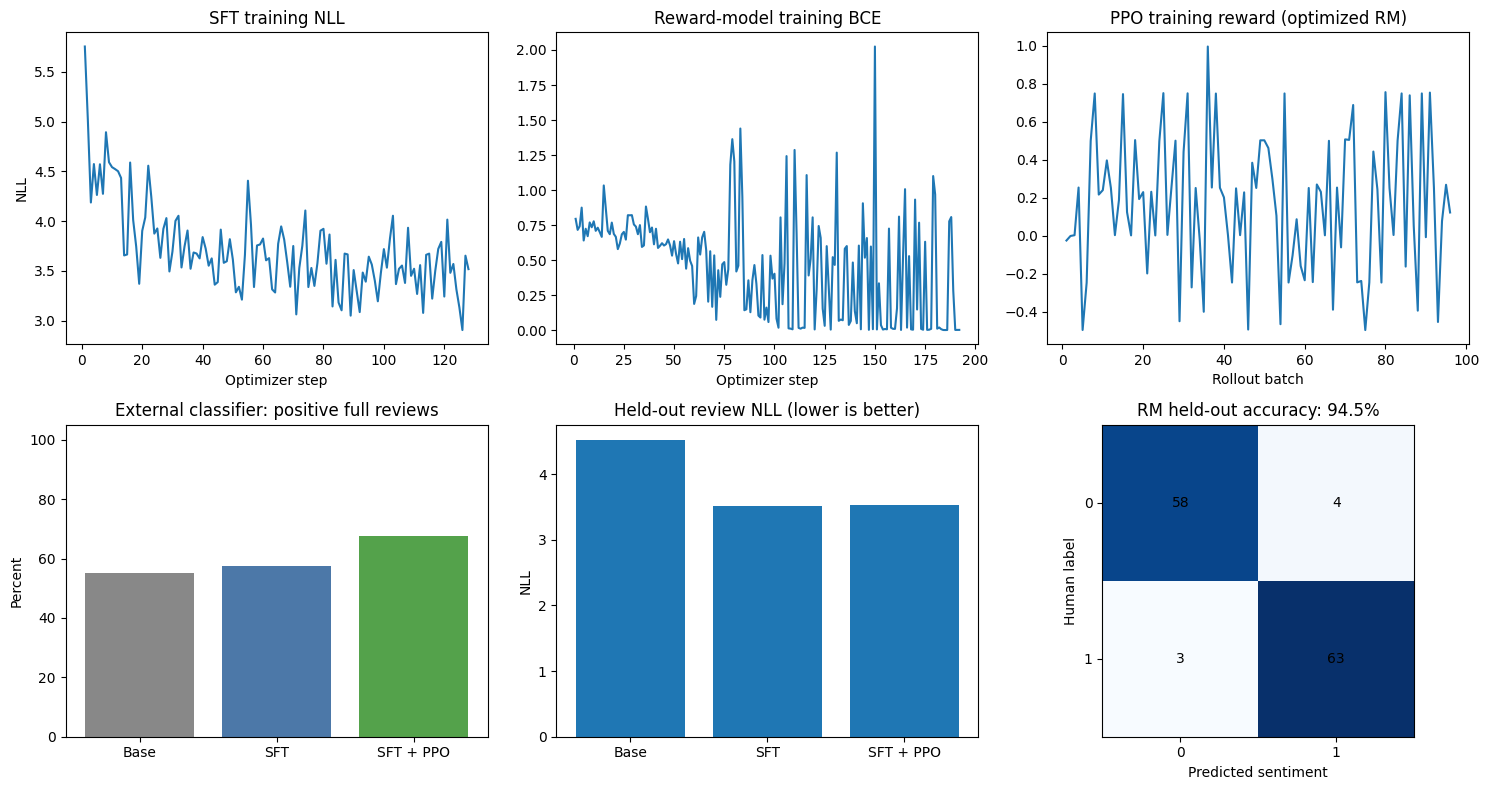

Profile: demo. Test prefixes per stage: 40.
SFT minus Base held-out NLL: -1.010 (negative means improved domain modeling).
PPO minus SFT external positive rate: +10.0%.
Reward-model held-out classification accuracy: 94.5%.
Positive sentiment is the chosen behavior, not a general response-quality or intelligence score.
No improvements are assumed. Inspect repetition, length, empty answers, and individual examples.


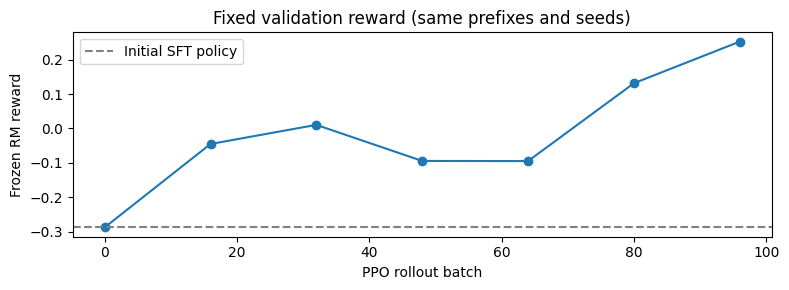

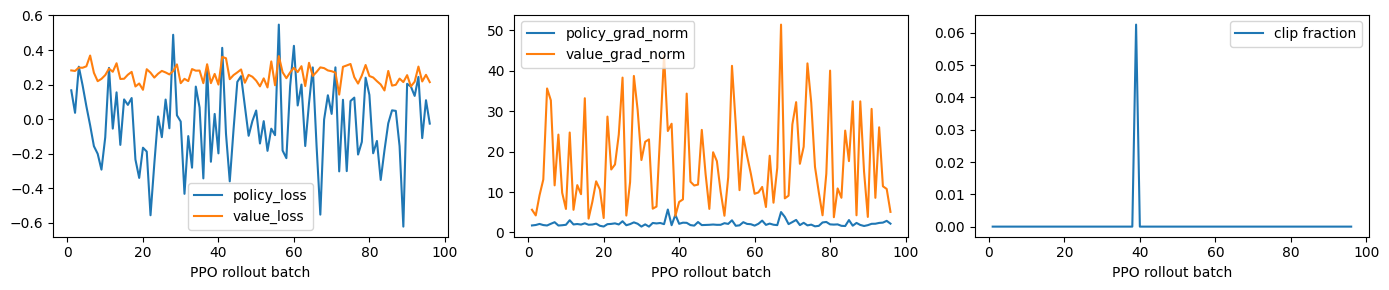

ZIP verified: /kaggle/working/qwen_sentiment_rlhf_clean_full_ppo_v2_final.zip (105.5 MiB)
Download from Kaggle's Output panel; confirm the local download completes.


PosixPath('/kaggle/working/qwen_sentiment_rlhf_clean_full_ppo_v2_final.zip')

In [10]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,3,figsize=(15,8))
sft_log=pd.DataFrame(json.loads((ROOT/"sft_log.json").read_text()))
rm_log=pd.DataFrame(json.loads((ROOT/"reward_log.json").read_text()))
ppo_log=pd.DataFrame(json.loads((ROOT/"ppo_log.json").read_text()))
axes[0,0].plot(sft_log.step,sft_log.loss); axes[0,0].set(title="SFT training NLL",xlabel="Optimizer step",ylabel="NLL")
axes[0,1].plot(rm_log.step,rm_log.bce); axes[0,1].set(title="Reward-model training BCE",xlabel="Optimizer step")
axes[0,2].plot(ppo_log.step,ppo_log.rm_reward); axes[0,2].set(title="PPO training reward (optimized RM)",xlabel="Rollout batch")
labels=["Base","SFT","SFT + PPO"]
axes[1,0].bar(labels,summary.positive_rate*100,color=["#888888","#4c78a8","#54a24b"])
axes[1,0].set(title="External classifier: positive full reviews",ylabel="Percent",ylim=(0,105))
axes[1,1].bar(labels,summary.review_nll); axes[1,1].set(title="Held-out review NLL (lower is better)",ylabel="NLL")
cm=np.zeros((2,2),dtype=int)
for y,p in zip(reward_test["labels"],reward_test["predictions"]): cm[y,p]+=1
axes[1,2].imshow(cm,cmap="Blues"); axes[1,2].set(title=f"RM held-out accuracy: {reward_test['accuracy']:.1%}",
    xlabel="Predicted sentiment",ylabel="Human label",xticks=[0,1],yticks=[0,1])
for i in range(2):
    for j in range(2): axes[1,2].text(j,i,str(cm[i,j]),ha="center",va="center")
fig.tight_layout(); fig.savefig(ROOT/"training_and_evaluation.png",dpi=160); display(fig); plt.close(fig)
change=summary.loc["ppo","positive_rate"]-summary.loc["sft","positive_rate"]
nll_change=summary.loc["sft","review_nll"]-summary.loc["baseline","review_nll"]
analysis=[f"Profile: {PROFILE}. Test prefixes per stage: {CFG['eval_n']}.",
 f"SFT minus Base held-out NLL: {nll_change:+.3f} (negative means improved domain modeling).",
 f"PPO minus SFT external positive rate: {change:+.1%}.",
 f"Reward-model held-out classification accuracy: {reward_test['accuracy']:.1%}.",
 "Positive sentiment is the chosen behavior, not a general response-quality or intelligence score.",
 "No improvements are assumed. Inspect repetition, length, empty answers, and individual examples."]
if PROFILE=="smoke": analysis.insert(0,"EXECUTION CHECK ONLY: too little training for an effectiveness claim.")
(ROOT/"analysis.txt").write_text("\n".join(analysis))
print("\n".join(analysis))

validation=pd.DataFrame(json.loads((ROOT/'ppo_validation.json').read_text()))
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(validation.step,validation.rm_reward,marker='o')
ax.axhline(validation.rm_reward.iloc[0],linestyle='--',color='gray',label='Initial SFT policy')
ax.set(title='Fixed validation reward (same prefixes and seeds)',xlabel='PPO rollout batch',ylabel='Frozen RM reward')
ax.legend();fig.tight_layout();fig.savefig(ROOT/'ppo_fixed_validation.png',dpi=160);display(fig);plt.close(fig)
diagnostics=pd.DataFrame(json.loads((ROOT/'ppo_log.json').read_text()))
fig,axes=plt.subplots(1,3,figsize=(14,3))
for column in ['policy_loss','value_loss']:axes[0].plot(diagnostics.step,diagnostics[column],label=column)
for column in ['policy_grad_norm','value_grad_norm']:axes[1].plot(diagnostics.step,diagnostics[column],label=column)
axes[2].plot(diagnostics.step,diagnostics.clip_fraction,label='clip fraction')
for ax in axes:ax.set_xlabel('PPO rollout batch');ax.legend()
fig.tight_layout();fig.savefig(ROOT/'ppo_update_diagnostics.png',dpi=160);display(fig);plt.close(fig)
backup('final')


### Interpretation of this run

SFT reduced held-out review NLL from approximately 4.53 to 3.52, indicating improved modeling of movie-review text.

The full-review positive rate increased from 57.5% after SFT to 67.5% after PPO. The continuation-only positive rate increased from 50.0% to 52.5%.

The reward model achieved 94.5% accuracy on its held-out classification split. This measures sentiment classification, not the overall quality of generated reviews.

The paired bootstrap interval for the PPO-minus-SFT sentiment-probability difference includes zero. This run suggests a sentiment-steering effect but does not establish a statistically reliable improvement.

## Original source license

Adapted from Ashwani Kumar’s RLHF in Notebooks, using Qwen3-4B with additional evaluation and visualization.
